# 선형 회귀

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/rickiepark/hg-mldl/blob/master/3-2.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />구글 코랩에서 실행하기</a>
  </td>
</table>

## k-최근접 이웃의 한계

In [49]:
import numpy as np

beak_length = np.array(
    [8.2, 8.5, 8.7, 9.0, 9.1, 9.3, 9.5, 9.7,
    9.8, 10.0, 8.8, 9.2, 9.6, 10.2, 8.6, 9.4,
    10.1, 8.9, 9.9, 10.3, 8.4, 9.0, 9.7, 10.0,
    8.7, 9.5, 10.4, 9.3, 8.9, 9.8, 10.1, 9.2,
    8.5, 9.6, 10.2,

    12.5, 13.0, 13.4, 13.8, 14.0, 14.3, 14.5, 14.8,
    15.0, 15.3, 12.8, 13.6, 14.2, 15.5]
     )
beak_height = np.array(
    [ 5.8, 6.1, 5.9, 6.3, 6.0, 6.5, 6.2, 6.7,
    6.4, 6.8, 6.1, 6.4, 6.0, 6.6, 5.7, 6.3,
    6.9, 6.2, 6.5, 6.7, 5.9, 6.1, 6.3, 6.4,
    6.0, 6.6, 6.8, 6.2, 5.8, 6.7, 6.5, 6.0,
    5.6, 6.1, 6.9,

    3.2, 3.0, 3.3, 2.9, 3.1, 2.8, 3.2, 2.7,
    3.0, 2.9, 3.1, 2.8, 3.0, 2.7]
     )

In [50]:
from sklearn.model_selection import train_test_split

# 훈련 세트와 테스트 세트로 나눕니다
train_input, test_input, train_target, test_target = train_test_split(
    beak_length, beak_height, random_state=42)
# 훈련 세트와 테스트 세트를 2차원 배열로 바꿉니다
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)

In [51]:
from sklearn.neighbors import KNeighborsRegressor

knr = KNeighborsRegressor(n_neighbors=3)
# k-최근접 이웃 회귀 모델을 훈련합니다
knr.fit(train_input, train_target)

KNeighborsRegressor(n_neighbors=3)

In [52]:
print(knr.predict([[10.0]]))

[6.7]


In [53]:
import matplotlib.pyplot as plt

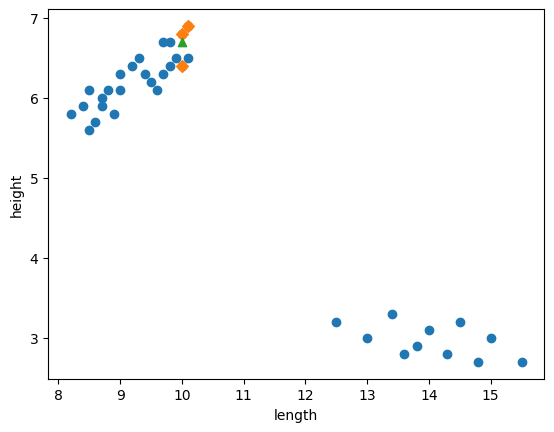

In [54]:
# 10cm 핀치새의 이웃을 구합니다
distances, indexes = knr.kneighbors([[10.0]])

# 훈련 세트의 산점도를 그립니다
plt.scatter(train_input, train_target)
# 훈련 세트 중에서 이웃 샘플만 다시 그립니다
plt.scatter(train_input[indexes], train_target[indexes], marker='D')
# 10cm 핀치 데이터
plt.scatter(10.0, 6.7, marker='^')
plt.xlabel('length')
plt.ylabel('height')
plt.show()

In [55]:
print(np.mean(train_target[indexes]))

6.7


In [56]:
print(knr.predict([[30.0]]))

[2.8]


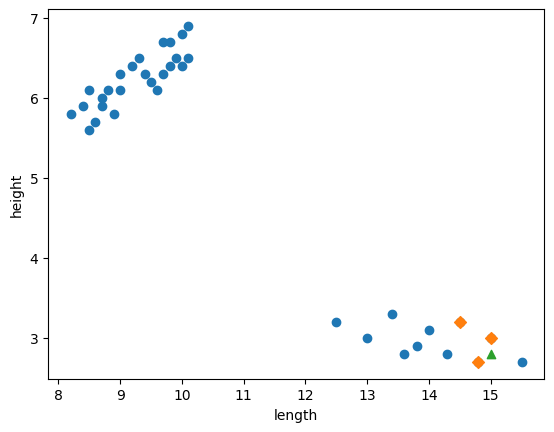

In [57]:
# 15.0cm 핀치새의 이웃을 구합니다
distances, indexes = knr.kneighbors([[15.0]])

# 훈련 세트의 산점도를 그립니다
plt.scatter(train_input, train_target)
# 훈련 세트 중에서 이웃 샘플만 다시 그립니다
plt.scatter(train_input[indexes], train_target[indexes], marker='D')
# 15.0cm 핀치새 데이터
plt.scatter(15.0, 2.8, marker='^')
plt.xlabel('length')
plt.ylabel('height')
plt.show()

## 선형 회귀

In [58]:
from sklearn.linear_model import LinearRegression

In [59]:
lr = LinearRegression()
# 선형 회귀 모델 훈련
lr.fit(train_input, train_target)

LinearRegression()

In [60]:
# 10.0cm 핀치새에 대한 예측
print(lr.predict([[30.0]]))

[-6.46214593]


In [61]:
print(lr.coef_, lr.intercept_)

[-0.60693929] 11.746032700587424


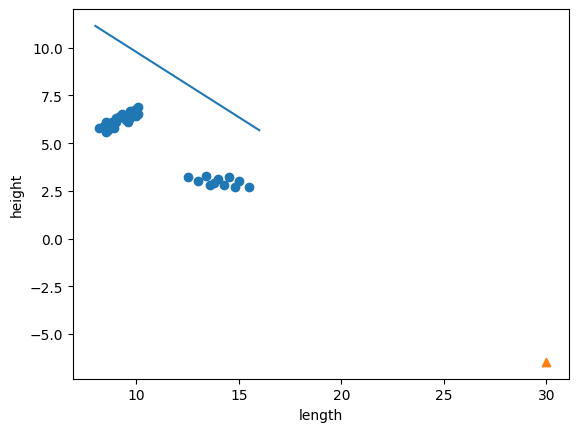

In [62]:
# 훈련 세트의 산점도를 그립니다
plt.scatter(train_input, train_target)
# 8에서 16까지 1차 방정식 그래프를 그립니다
plt.plot([8, 16], [1*lr.coef_+lr.intercept_, 10*lr.coef_+lr.intercept_])
# 10cm 핀치새 데이터
plt.scatter(30.0, -6.46, marker='^')
plt.xlabel('length')
plt.ylabel('height')
plt.show()

In [63]:
print(lr.score(train_input, train_target))
print(lr.score(test_input, test_target))

0.8296606122529694
0.7235327862477787


## 다항 회귀

In [64]:
train_poly = np.column_stack((train_input ** 2, train_input))
test_poly = np.column_stack((test_input ** 2, test_input))

In [65]:
print(train_poly.shape, test_poly.shape)

(36, 2) (13, 2)


In [66]:
lr = LinearRegression()
lr.fit(train_poly, train_target)

print(lr.predict([[10**2, 10]]))

[5.93124263]


In [67]:
print(lr.coef_, lr.intercept_)

[-0.07425585  1.12652006] 2.0916265828789156


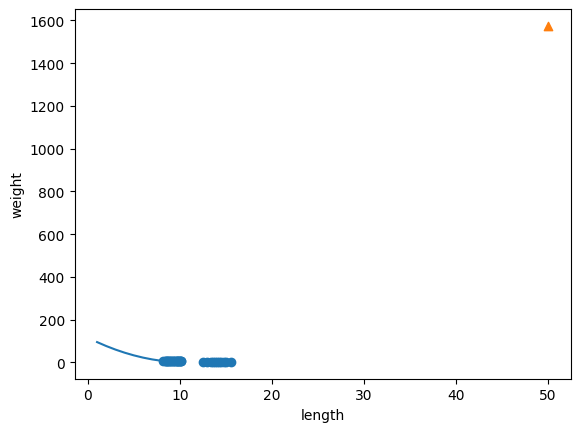

In [68]:
# 구간별 직선을 그리기 위해 1에서 9까지 정수 배열을 만듭니다
point = np.arange(1, 10)
# 훈련 세트의 산점도를 그립니다
plt.scatter(train_input, train_target)
# 1에서 9까지 2차 방정식 그래프를 그립니다
plt.plot(point, 1.01*point**2 - 21.6*point + 116.05)
# 50cm 농어 데이터
plt.scatter([50], [1574], marker='^')
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [69]:
print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))

0.8550852587515511
0.7744527515774406
